In [141]:
from sklearn.datasets import make_moons

def sample_moons(n, noise=0.05, scale=2.0):
    X, _ = make_moons(n_samples=n, noise=noise)
    return (X - X.mean(axis=0)) * scale

In [142]:
import numpy as np

def sample_checkerboard(n, k=4, size=4.0):
    pts = []
    while len(pts) < n:
        p = np.random.uniform(-size, size, (2 * n, 2))
        cell = np.floor((p + size) / (2 * size / k)).astype(int)
        keep = (cell[:, 0] + cell[:, 1]) % 2 == 0
        pts.extend(p[keep])
    return np.array(pts[:n])

In [143]:
def sample_gaussian_mixture(n, K=8, R=4.0, std=0.4):
    angles = np.linspace(0, 2 * np.pi, K, endpoint=False)
    centers = np.stack([R * np.cos(angles), R * np.sin(angles)], axis=1)
    idx = np.random.randint(0, K, size=n)
    return centers[idx] + std * np.random.randn(n, 2)

In [144]:
import matplotlib.pyplot as plt

X_gaussian = sample_gaussian_mixture(50000)
X_moons = sample_moons(50000)
X_checkerboard = sample_checkerboard(50000)

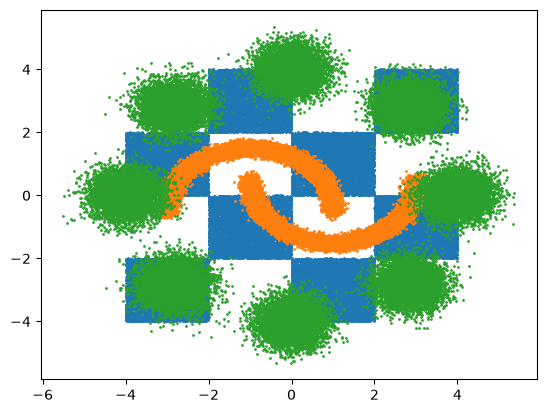

In [145]:
plt.scatter(*X_checkerboard.T, s=1)
plt.scatter(*X_moons.T, s=1)
plt.scatter(*X_gaussian.T, s=1)

In [146]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [147]:
gaussian = torch.tensor(X_gaussian, dtype=torch.float32)
moons = torch.tensor(X_moons, dtype=torch.float32)
checkerboard = torch.tensor(X_checkerboard, dtype=torch.float32)

In [148]:
import sys
sys.path.append('..')
from p0.models import MLP

def train(x1_data, n_iters=10000, lr=1e-2, x0_data=None):
    model = MLP()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    losses = []
    B = 512
    for _ in range(n_iters):
        batch_idx = torch.randint(0, len(x1_data), (B,))
        x1 = x1_data[batch_idx]
        if x0_data is None:
            x0 = torch.randn_like(x1)
        else:
            x0 = x0_data[batch_idx]
        t = torch.rand(B, 1)
        xt = x0 * (1 - t) + x1 * t
        target = x1 - x0
        pred = model(xt, t)
        loss = F.mse_loss(pred, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return (model, losses)

# 1-RF

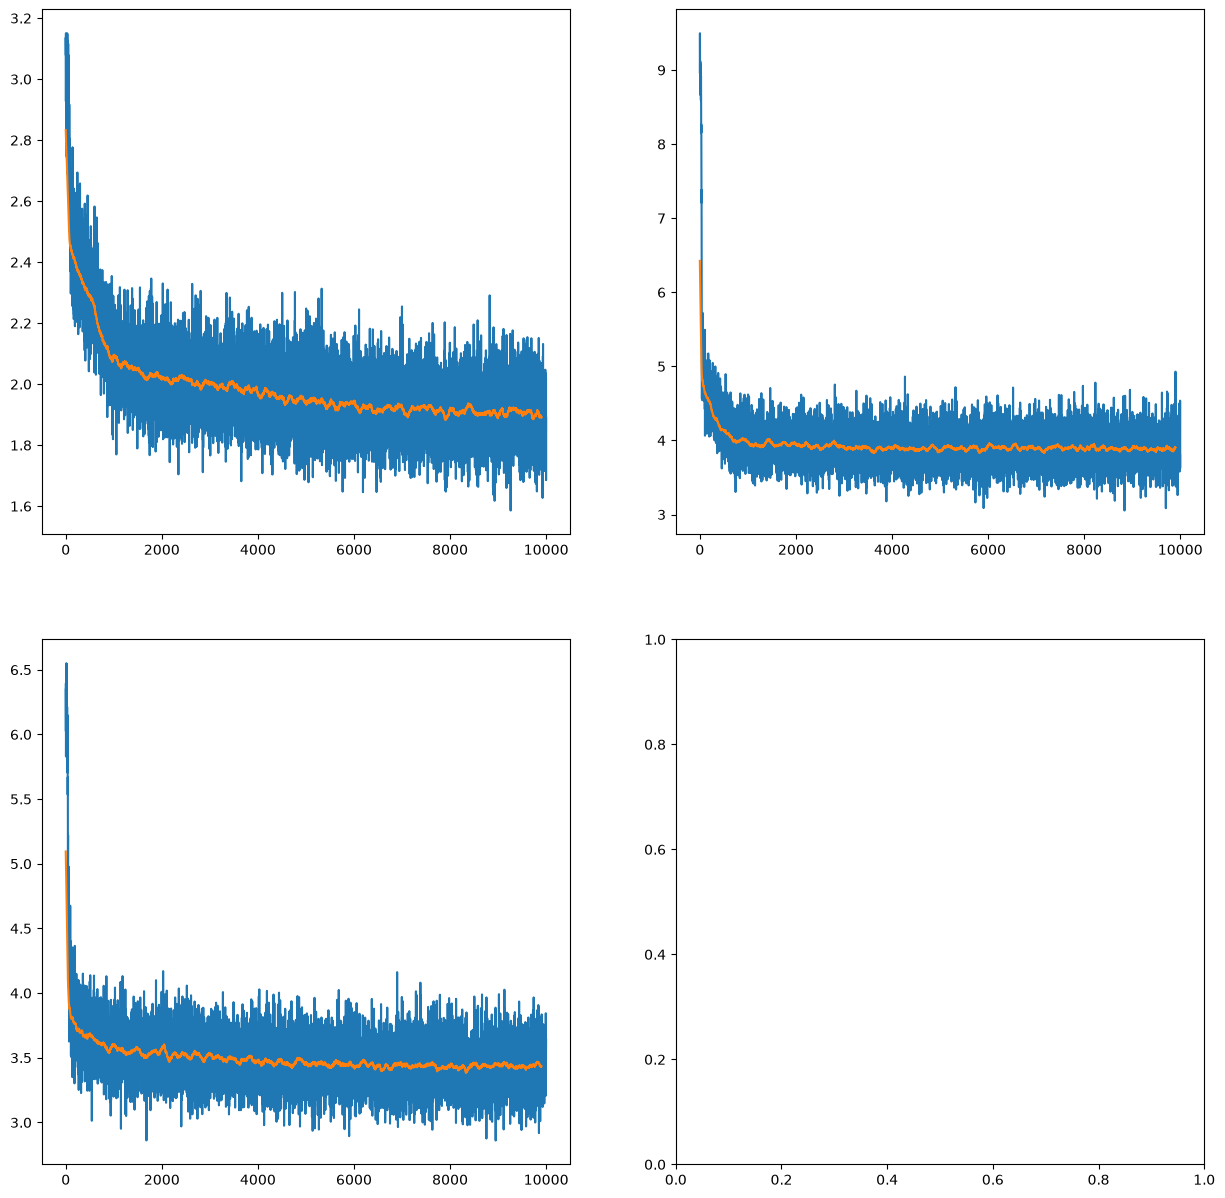

In [149]:
fig, axes = plt.subplots(2, 2, figsize=(15,15))

model_moons, losses_moons = train(moons)
axes[0, 0].plot(losses_moons)
axes[0, 0].plot(np.convolve(losses_moons, np.ones(100) / 100, mode='valid'))

model_gaussian, losses_gaussian = train(gaussian)
axes[0, 1].plot(losses_gaussian)
axes[0, 1].plot(np.convolve(losses_gaussian, np.ones(100) / 100, mode='valid'))

model_checkerboard, losses_checkerboard = train(checkerboard)
axes[1, 0].plot(losses_checkerboard)
axes[1, 0].plot(np.convolve(losses_checkerboard, np.ones(100) / 100, mode='valid'))

In [150]:
def make_drift(model):
    def drift(x, t):
        t = torch.as_tensor(t, dtype=x.dtype).reshape(-1, 1).expand(x.shape[0], 1)
        return model(x, t)
    return drift

In [151]:
from p0.integrators import euler_maruyama

def generate(model, z0, ts, return_traj=True):
    with torch.no_grad():
        return euler_maruyama(make_drift(model), None, z0, ts, return_traj=return_traj)
        

In [ ]:
z0_traj = torch.randn(2000, 2)
ts = torch.linspace(0, 1, 101)
traj_moons = generate(model_moons, z0_traj, ts)
traj_gaussian = generate(model_gaussian, z0_traj, ts)
traj_checkerboard = generate(model_checkerboard, z0_traj, ts)

In [153]:
def plot_trajs(ax, traj, title='', n_show=200):
    traj = traj.numpy()
    ax.plot(traj[:, :n_show, 0], traj[:, :n_show, 1], linewidth=0.5, alpha=0.4)
    ax.scatter(traj[0, :n_show, 0], traj[0, :n_show, 1], s=5, color='tab:blue', label='t=0')
    ax.scatter(traj[-1, :n_show, 0], traj[-1, :n_show, 1], s=5, color='tab:red', label='t=1')
    ax.set_title(title)
    ax.set_axis_off()

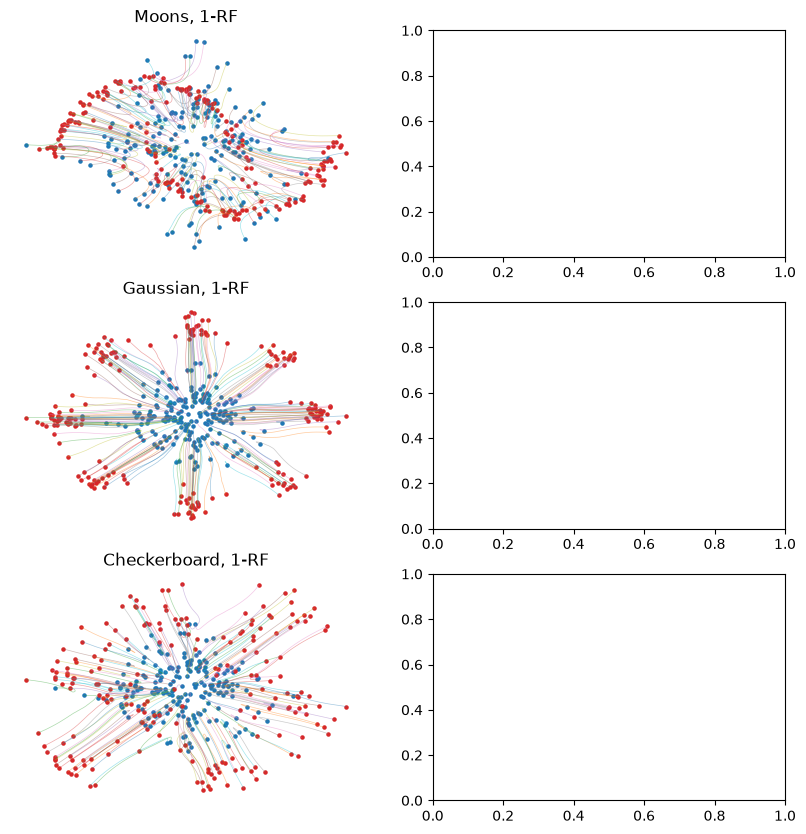

In [154]:
fig_traj, axes_traj = plt.subplots(3, 2, figsize=(10, 10))
plot_trajs(ax=axes_traj[0, 0], traj=traj_moons, title='Moons, 1-RF')
plot_trajs(ax=axes_traj[1, 0], traj=traj_gaussian, title='Gaussian, 1-RF')
plot_trajs(ax=axes_traj[2, 0], traj=traj_checkerboard, title='Checkerboard, 1-RF')

In [155]:
def straightness(traj):
    N = traj.shape[0] - 1
    straight = traj[-1] - traj[0]
    v = (traj[1:] - traj[:-1]) * N
    return float(((straight - v) ** 2).sum(dim=2).mean())

In [156]:
straightness_moons = straightness(traj_moons)
straightness_gaussian = straightness(traj_gaussian)
straightness_checkerboard = straightness(traj_checkerboard)
print(f'{straightness_moons=}\n{straightness_gaussian=}\n{straightness_checkerboard=}')

straightness_moons=1.3249293565750122
straightness_gaussian=3.005014419555664
straightness_checkerboard=2.0408778190612793


# 2-RF

In [157]:
z0 = torch.randn(50000, 2)
z1_moons = generate(model_moons, z0, ts)[-1]
z1_gaussian = generate(model_gaussian, z0, ts)[-1]
z1_checkerboard = generate(model_checkerboard, z0, ts)[-1]

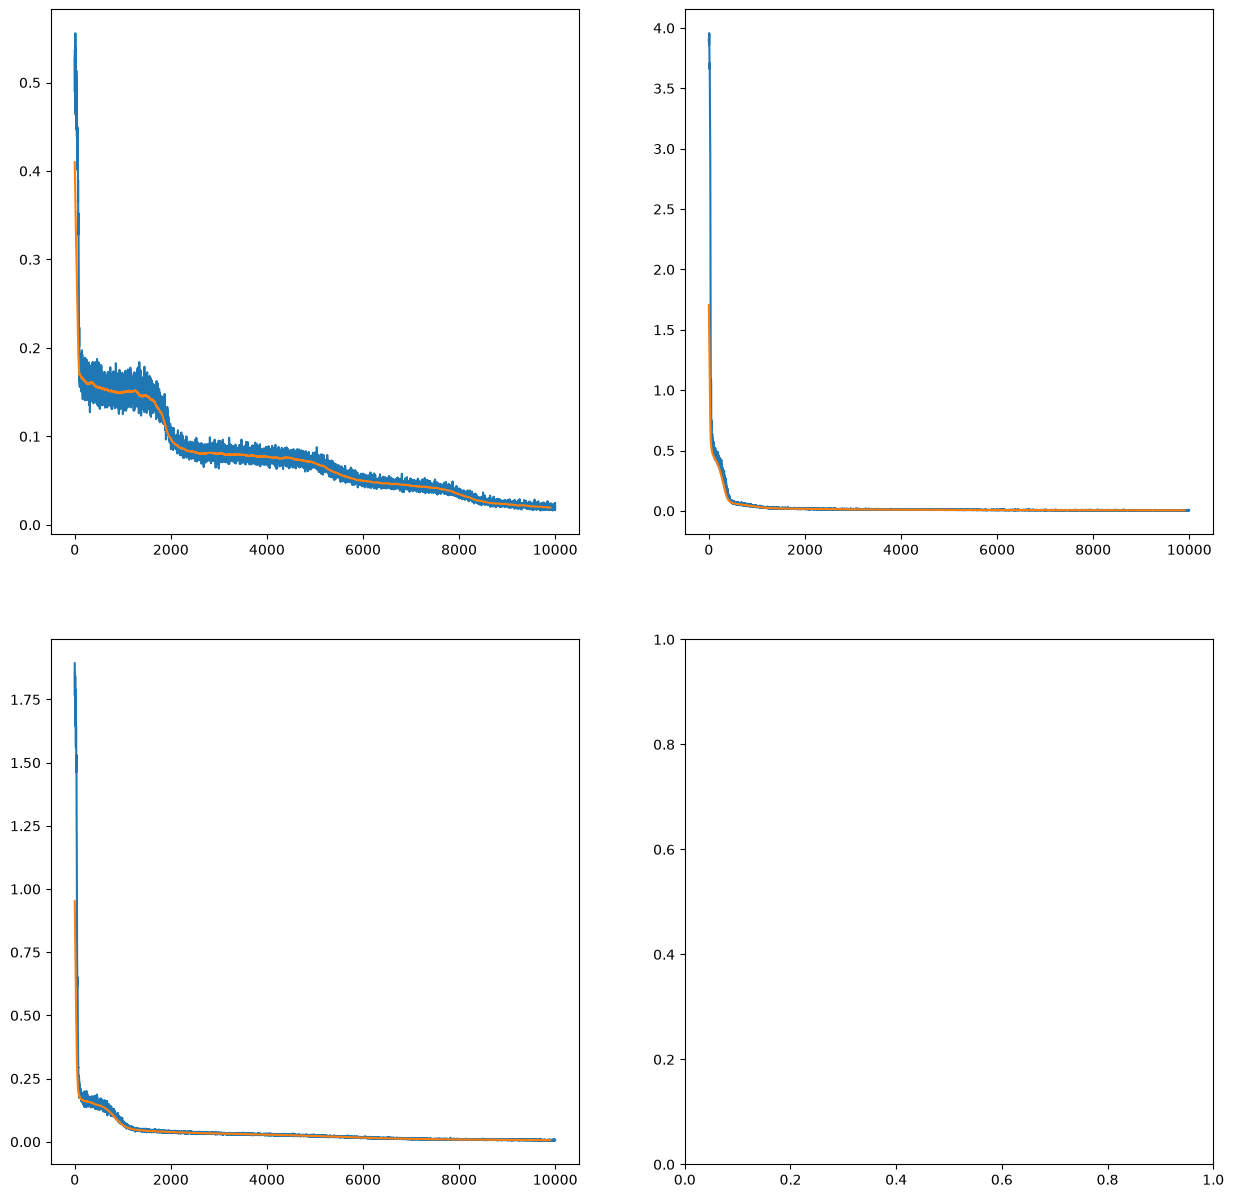

In [158]:
fig, axes = plt.subplots(2, 2, figsize=(15,15))

model_moons, losses_moons = train(x0_data=z0, x1_data=z1_moons)
axes[0, 0].plot(losses_moons)
axes[0, 0].plot(np.convolve(losses_moons, np.ones(100) / 100, mode='valid'))

model_gaussian, losses_gaussian = train(x0_data=z0, x1_data=z1_gaussian)
axes[0, 1].plot(losses_gaussian)
axes[0, 1].plot(np.convolve(losses_gaussian, np.ones(100) / 100, mode='valid'))

model_checkerboard, losses_checkerboard = train(x0_data=z0, x1_data=z1_checkerboard)
axes[1, 0].plot(losses_checkerboard)
axes[1, 0].plot(np.convolve(losses_checkerboard, np.ones(100) / 100, mode='valid'))

In [159]:
ts = torch.linspace(0, 1, 101)
traj_moons = generate(model_moons, z0_traj, ts)
traj_gaussian = generate(model_gaussian, z0_traj, ts)
traj_checkerboard = generate(model_checkerboard, z0_traj, ts)

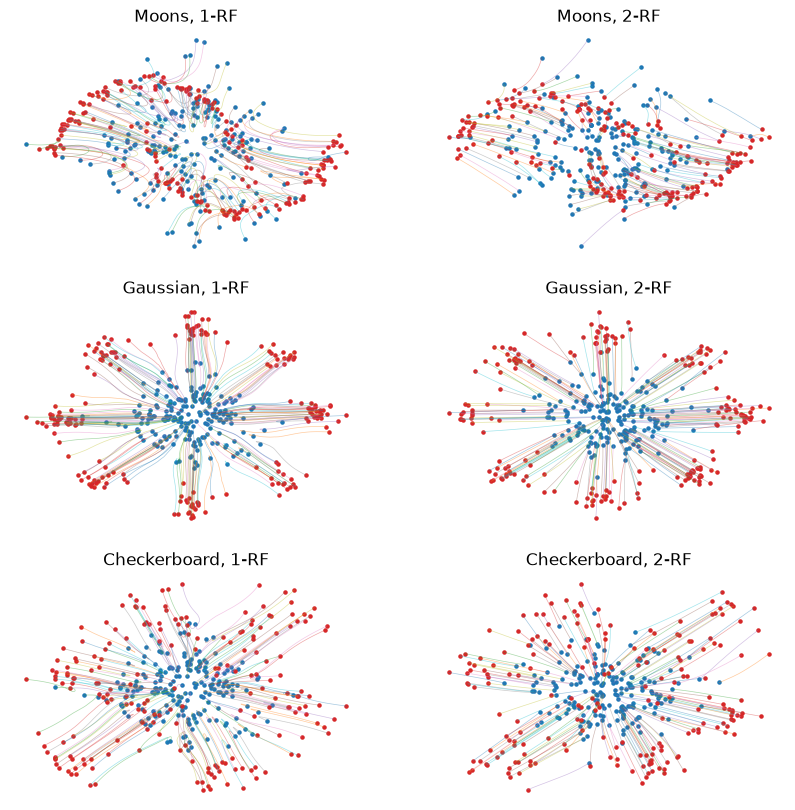

In [160]:
plot_trajs(ax=axes_traj[0, 1], traj=traj_moons, title='Moons, 2-RF')
plot_trajs(ax=axes_traj[1, 1], traj=traj_gaussian, title='Gaussian, 2-RF')
plot_trajs(ax=axes_traj[2, 1], traj=traj_checkerboard, title='Checkerboard, 2-RF')
fig_traj